# Impact des data centers en France — visualisations
Prérequis : `pip install pandas numpy matplotlib squarify folium`
Le fichier `export_summary.csv` doit être dans le même dossier que ce notebook. Les images sont enregistrées dans `figures/`.

## 0. Chargement et nettoyage (à exécuter en premier)

In [1]:
import os, json, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import squarify

VERT, ORANGE, GRIS, ENCRE = "#1f7a6d", "#d9822b", "#9a9a94", "#222222"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.edgecolor": "#888", "axes.labelcolor": ENCRE, "text.color": ENCRE,
})
os.makedirs("figures", exist_ok=True)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")          # 1 400 au lieu de 1,400
fmtlog = lambda v, _=None: (f"{v:g}" if v < 1000 else fmt(v))   # graduations log : 0.1, 1, 10, 1 000

# --- Chargement ---
df = pd.read_csv("export_summary.csv")
df = df[df["country"] == "France"].copy()

# --- Régions : apostrophes + doublons d'écriture ---
df["region"] = (df["region"].str.replace("\\,", "'", regex=False).str.strip()
                  .replace({"Grand-Est": "Grand Est", "Centre-Val De Loire": "Centre-Val de Loire",
                            "La réunion": "La Réunion"})
                  .fillna("Région inconnue"))

# --- Opérateurs : regroupement des variantes d'écriture ---
REGLES = [("interxion", "Digital Realty / Interxion"), ("digital real", "Digital Realty / Interxion"),
          ("equinix", "Equinix"), ("data4", "Data4"), ("ovh", "OVHcloud"), ("etix", "Etix Everywhere"),
          ("telehouse", "Telehouse"), ("orange", "Orange"), ("ibm", "IBM / Kyndryl"), ("atos", "Atos")]
def operateur(v):
    s = "" if pd.isna(v) else str(v).replace("\\,", "'").strip()
    if not s or s.upper() == "TO BE IDENTIFIED":
        return "Opérateur inconnu"
    for cle, nom in REGLES:
        if cle in s.lower():
            return nom
    return s
df["operateur"] = df["operator"].map(operateur)

# --- Statut, puissance (0 MW = valeur manquante), année ---
df["statut"] = np.where(df["progress_step"] == "operating", "En service", "En projet")
df["mw"] = df["power_total_mw"].replace(0, np.nan)
df["annee"] = df["operation_start_year"]

# --- Couverture des données (à citer dans la présentation) ---
n, n_mw, n_an = len(df), df["mw"].notna().sum(), df["annee"].notna().sum()
print(f"{n} sites | puissance connue : {n_mw} ({n-n_mw} manquantes dont "
      f"{(df.power_total_mw == 0).sum()} à 0 MW) | année connue : {n_an} ({n-n_an} manquantes)")
print(df.groupby("statut").agg(sites=("name", "size"), avec_puissance=("mw", "count"),
                               MW_total=("mw", "sum"), avec_annee=("annee", "count")).round(0))

426 sites | puissance connue : 391 (35 manquantes dont 8 à 0 MW) | année connue : 272 (154 manquantes)
            sites  avec_puissance  MW_total  avec_annee
statut                                                 
En projet      84              55    7395.0          36
En service    342             336    2224.0         236


## 1. Capacité en service vs en projet par région
À gauche : barres empilées (échelle linéaire, l'Île-de-France domine). À droite : barres jumelées en échelle log pour lire les petites régions.

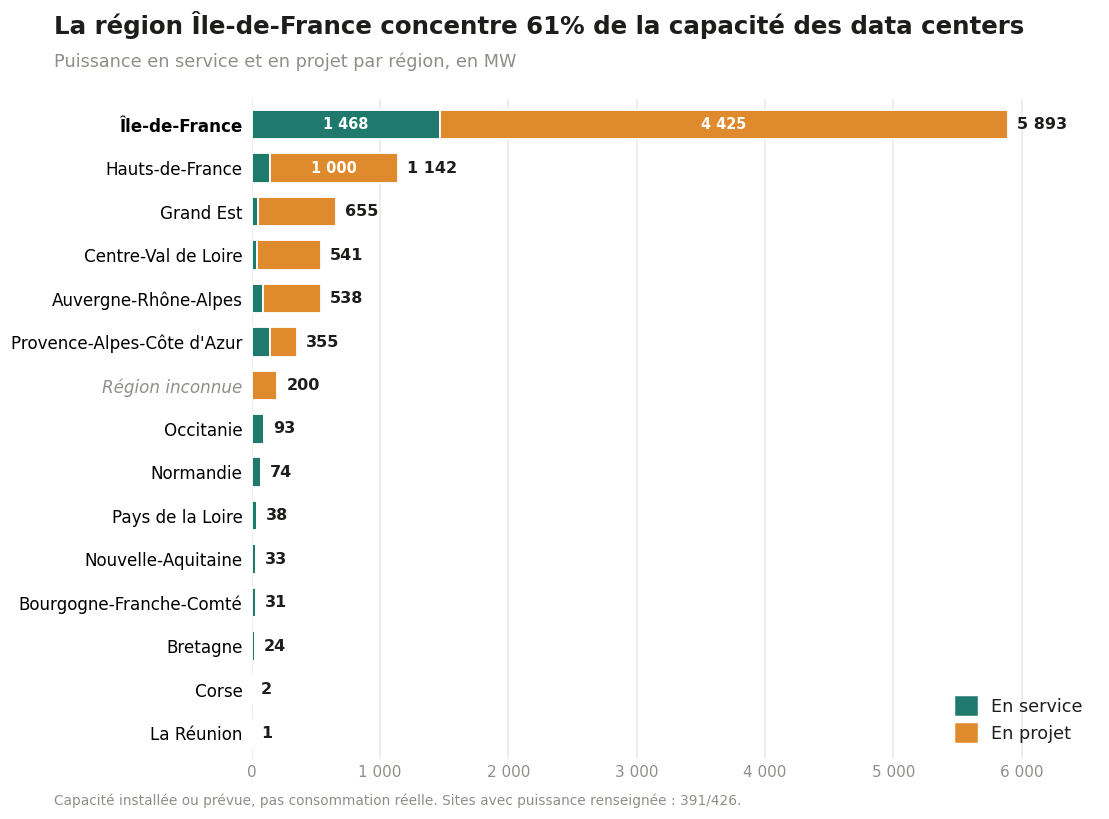

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from matplotlib.patches import Patch
import os

VERT, ORANGE, GRIS, ENCRE = "#1f7a6d", "#e08a2e", "#8f8f89", "#1d1d1b"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "font.size": 11,
                     "text.color": ENCRE, "axes.labelcolor": ENCRE})
os.makedirs("figures", exist_ok=True)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

# --- Données ---
df = pd.read_csv("export_summary.csv")
df = df[df["country"] == "France"].copy()
df["region"] = (df["region"].str.replace("\\,", "'", regex=False).str.strip()
                  .replace({"Grand-Est": "Grand Est", "Centre-Val De Loire": "Centre-Val de Loire",
                            "La réunion": "La Réunion", "Ile-de-France": "Île-de-France"})
                  .fillna("Région inconnue"))
df["statut"] = np.where(df["progress_step"] == "operating", "En service", "En projet")
df["mw"] = df["power_total_mw"].replace(0, np.nan)      # 0 MW = valeur manquante
n, n_mw = len(df), df["mw"].notna().sum()

reg = (df.dropna(subset=["mw"]).pivot_table(index="region", columns="statut", values="mw",
                                            aggfunc="sum", fill_value=0)
         .reindex(columns=["En service", "En projet"], fill_value=0))
reg["total"] = reg.sum(axis=1)
reg = reg.sort_values("total")
y = np.arange(len(reg))
top, vmax = reg.index[-1], reg["total"].max()
part_top = reg["total"].iloc[-1] / reg["total"].sum()

# --- Figure ---
fig, ax = plt.subplots(figsize=(10, 7.6))
H = .68
ax.barh(y, reg["En service"], height=H, color=VERT, edgecolor="white", linewidth=1.2, zorder=3)
ax.barh(y, reg["En projet"], left=reg["En service"], height=H, color=ORANGE,
        edgecolor="white", linewidth=1.2, zorder=3)

for yi, (nom, r) in zip(y, reg.iterrows()):
    # total au bout de la barre
    ax.text(r["total"] + vmax * .012, yi, fmt(r["total"]), va="center", ha="left",
            fontsize=10.5, fontweight="bold", color=ENCRE, zorder=4)
    # détail dans les segments assez larges
    if r["En service"] > vmax * .12:
        ax.text(r["En service"] / 2, yi, fmt(r["En service"]), va="center", ha="center",
                color="white", fontsize=9.5, fontweight="bold", zorder=4)
    if r["En projet"] > vmax * .12:
        ax.text(r["En service"] + r["En projet"] / 2, yi, fmt(r["En projet"]), va="center", ha="center",
                color="white", fontsize=9.5, fontweight="bold", zorder=4)

# Axes épurés
ax.set_yticks(y, reg.index, fontsize=11)
for lab in ax.get_yticklabels():
    if lab.get_text() == "Région inconnue":
        lab.set_color(GRIS); lab.set_style("italic")
    elif lab.get_text() == top:
        lab.set_fontweight("bold")
ax.set_xlim(0, vmax * 1.12)
ax.set_ylim(-.6, len(reg) - .4)
ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: fmt(v)))
ax.xaxis.set_major_locator(mt.MultipleLocator(1000))
ax.tick_params(axis="x", colors=GRIS, labelsize=10, length=0)
ax.tick_params(axis="y", length=0, pad=6)
ax.set_axisbelow(True)
ax.xaxis.grid(True, color="#e8e8e3", linewidth=1, zorder=0)
for s in ax.spines.values():
    s.set_visible(False)

# Légende
ax.legend(handles=[Patch(color=VERT, label="En service"), Patch(color=ORANGE, label="En projet")],
          loc="lower right", frameon=False, fontsize=11.5, handlelength=1.2, handleheight=1.2)

# Titres
fig.text(.02, .965, f"La région {top} concentre {part_top:.0%} de la capacité des data centers",
         fontsize=16, fontweight="bold", ha="left", va="top")
fig.text(.02, .915, "Puissance en service et en projet par région, en MW", fontsize=11.5, color=GRIS, ha="left", va="top")
fig.text(.02, .015, f"Capacité installée ou prévue, pas consommation réelle. Sites avec puissance renseignée : {n_mw}/{n}.",
         fontsize=9, color=GRIS, ha="left")

plt.subplots_adjust(left=.2, right=.97, top=.86, bottom=.07)
plt.savefig("figures/1_regions.png", bbox_inches="tight", facecolor="white")
plt.show()

## 2. Puissance cumulée par année de mise en service
Seuls les sites ayant **à la fois** une année et une puissance sont comptés (voir le bandeau de couverture en bas du graphique).

In [4]:
ANNEE_COURANTE = 2026
d = df.dropna(subset=["mw", "annee"]).copy()
annees = np.arange(1985, 2036)

par_an = (d.groupby(["annee", "statut"]).mw.sum().unstack(fill_value=0)
            .reindex(annees, fill_value=0).reindex(columns=["En service", "En projet"], fill_value=0))
cum = par_an.cumsum()

fig, (ax, ax_b) = plt.subplots(2, 1, figsize=(12, 8.5), sharex=True, gridspec_kw={"height_ratios": [2.3, 1]})

ax.stackplot(annees, cum["En service"], cum["En projet"], colors=[VERT, ORANGE], alpha=.85,
             labels=["En service", "En projet"])
ax.axvline(ANNEE_COURANTE, color=ENCRE, ls=":", lw=1)
ax.text(ANNEE_COURANTE - .4, ax.get_ylim()[1] * .97, "2026", ha="right", va="top", fontsize=10)
ax.set_ylabel("Puissance cumulée (MW)")
ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: fmt(v)))
ax.set_title("Puissance cumulée des data centers français")
ax.legend(frameon=False, loc="upper left")

# Annotation de l'année qui concentre le plus de nouveaux MW
pic = int(par_an.sum(axis=1).idxmax())
gros = d[d.annee == pic].nlargest(1, "mw").iloc[0]
ax.annotate(f"{pic} : {fmt(par_an.loc[pic].sum())} MW prévus,\ndont {gros['name'].strip()} ({fmt(gros['mw'])} MW)",
            xy=(pic, cum.loc[pic].sum()), xytext=(pic - 22, cum.sum(axis=1).max() * .62),
            arrowprops=dict(arrowstyle="->", color=ENCRE), fontsize=9.5, ha="left")

ax_b.bar(annees, par_an["En service"], color=VERT, width=.8)
ax_b.bar(annees, par_an["En projet"], bottom=par_an["En service"], color=ORANGE, width=.8)
ax_b.axvline(ANNEE_COURANTE, color=ENCRE, ls=":", lw=1)
ax_b.set_ylabel("Nouveaux MW / an")
ax_b.set_xlim(1985, 2035)
ax_b.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: fmt(v)))

fig.text(.01, .005, f"Couverture : {len(d)} sites sur {n} ont une année ET une puissance ({fmt(d.mw.sum())} MW sur "
         f"{fmt(df.mw.sum())} MW). Les {n - n_an} sites sans année ne sont pas représentés.", fontsize=9, color=GRIS)
plt.tight_layout(rect=(0, .02, 1, 1))
plt.savefig("figures/2_cumul_annees.png", bbox_inches="tight")
plt.show()

KeyError: ['annee']

## 3. Qui concentre la capacité ? (barres puis treemap)

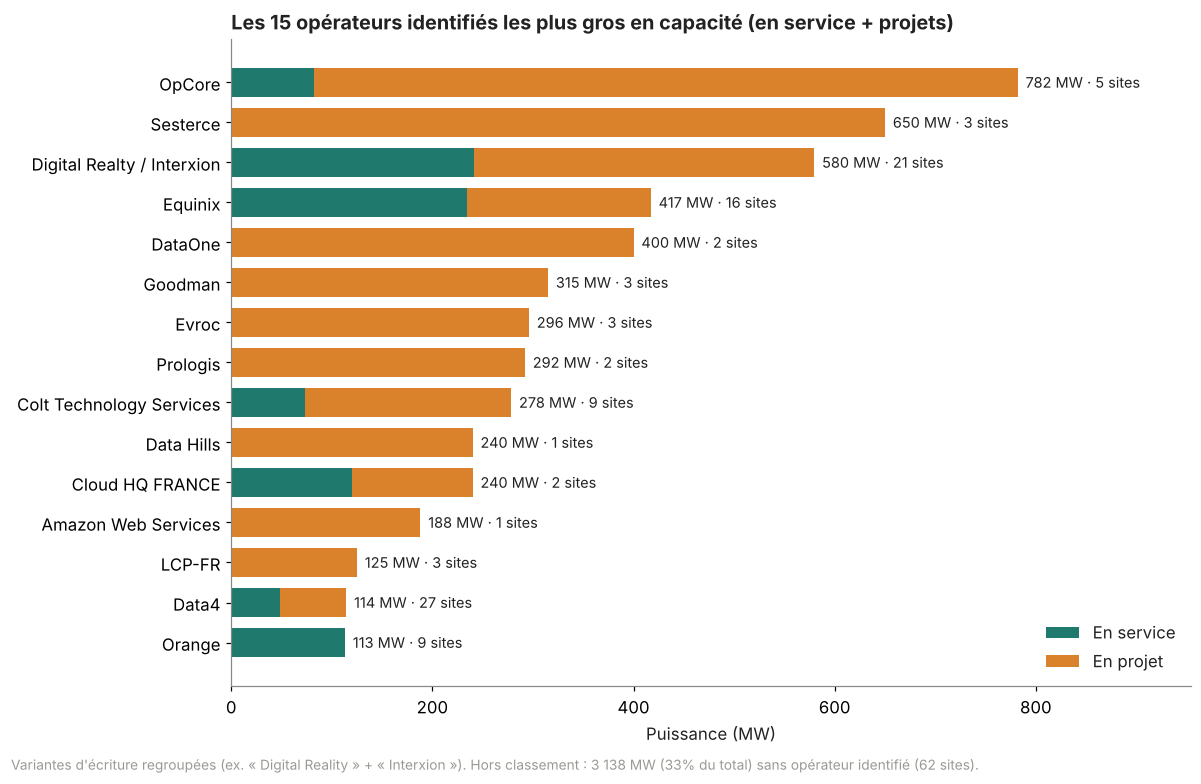

In [4]:
op = (df.dropna(subset=["mw"]).groupby(["operateur", "statut"]).mw.sum().unstack(fill_value=0)
        .reindex(columns=["En service", "En projet"], fill_value=0))
op["total"] = op.sum(axis=1)
nb_sites = df.groupby("operateur").size()
inconnu_mw = op.loc["Opérateur inconnu", "total"]
top = op.drop(index="Opérateur inconnu").sort_values("total", ascending=False).head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(top))
ax.barh(y, top["En service"], color=VERT, height=.72, label="En service")
ax.barh(y, top["En projet"], left=top["En service"], color=ORANGE, height=.72, label="En projet")
for yi, (nom, r) in zip(y, top.iterrows()):
    ax.text(r["total"] + top["total"].max() * .01, yi, f"{fmt(r['total'])} MW · {nb_sites[nom]} sites",
            va="center", fontsize=9.5)
ax.set_yticks(y, top.index)
ax.set_xlim(right=top["total"].max() * 1.22)
ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: fmt(v)))
ax.set_xlabel("Puissance (MW)")
ax.set_title("Les 15 opérateurs identifiés les plus gros en capacité (en service + projets)")
ax.legend(frameon=False, loc="lower right")
fig.text(.01, -.01, f"Variantes d'écriture regroupées (ex. « Digital Reality » + « Interxion »). Hors classement : {fmt(inconnu_mw)} MW "
         f"({inconnu_mw / op['total'].sum():.0%} du total) sans opérateur identifié ({nb_sites['Opérateur inconnu']} sites).", fontsize=9, color=GRIS)
plt.tight_layout()
plt.savefig("figures/3a_operateurs_barres.png", bbox_inches="tight")
plt.show()

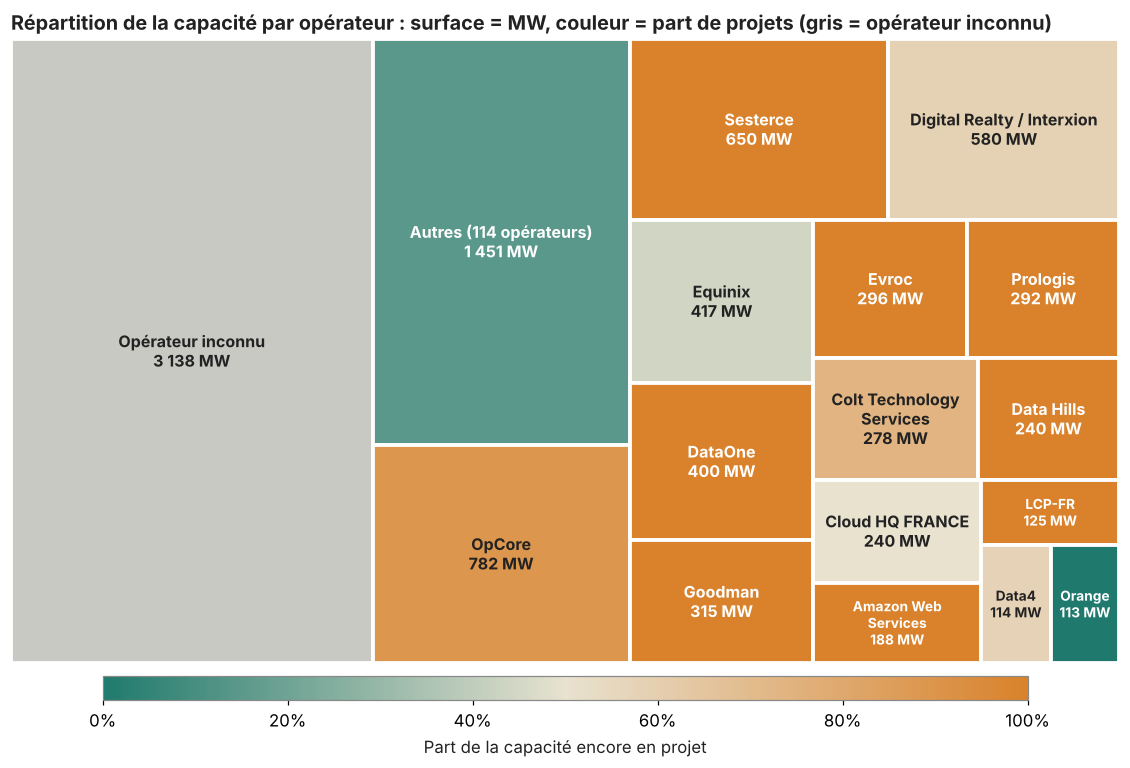

In [5]:
# Treemap : surface = MW total ; couleur = part de projets (vert = existant, orange = futur) ; gris = opérateur inconnu
import textwrap
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap, to_rgb

t = op[op["total"] > 0].sort_values("total", ascending=False).copy()
t["part_projet"] = t["En projet"] / t["total"]
N = 16
principaux = t.head(N)
if "Opérateur inconnu" not in principaux.index:
    principaux = pd.concat([principaux, t.loc[["Opérateur inconnu"]]])
reste = t.drop(index=principaux.index)
if len(reste):
    principaux = pd.concat([principaux, pd.DataFrame(
        {"En service": reste["En service"].sum(), "En projet": reste["En projet"].sum(), "total": reste["total"].sum(),
         "part_projet": reste["En projet"].sum() / reste["total"].sum()}, index=[f"Autres ({len(reste)} opérateurs)"])])
principaux = principaux.sort_values("total", ascending=False)

cmap = LinearSegmentedColormap.from_list("vo", [VERT, "#e8e2d0", ORANGE])
W, H = 100, 60
rects = squarify.squarify(squarify.normalize_sizes(principaux["total"].tolist(), W, H), 0, 0, W, H)

fig, ax = plt.subplots(figsize=(13, 7.8))
for (nom, r), q in zip(principaux.iterrows(), rects):
    inconnu = nom == "Opérateur inconnu"
    col = "#c9c9c4" if inconnu else cmap(r.part_projet)
    ax.add_patch(Rectangle((q["x"], q["y"]), q["dx"], q["dy"], facecolor=col, edgecolor="white", linewidth=2.5))
    lum = 0.299 * to_rgb(col)[0] + 0.587 * to_rgb(col)[1] + 0.114 * to_rgb(col)[2]
    tc = ENCRE if lum > .6 else "white"
    if q["dx"] * q["dy"] > 45:                                   # pas de texte dans les cases trop petites
        nom_aff = "\n".join(textwrap.wrap(nom, max(8, int(q["dx"] * 1.25))))
        ax.text(q["x"] + q["dx"] / 2, q["y"] + q["dy"] / 2, f"{nom_aff}\n{fmt(r.total)} MW", ha="center", va="center",
                color=tc, fontsize=9 if q["dx"] * q["dy"] < 120 else 10.5, fontweight="bold")
ax.set_xlim(0, W); ax.set_ylim(0, H); ax.invert_yaxis(); ax.axis("off")
ax.set_title("Répartition de la capacité par opérateur : surface = MW, couleur = part de projets (gris = opérateur inconnu)")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
cb = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=.035, pad=.02, aspect=40)
cb.set_label("Part de la capacité encore en projet"); cb.ax.xaxis.set_major_formatter(mt.PercentFormatter(1))
plt.savefig("figures/3b_operateurs_treemap.png", bbox_inches="tight")
plt.show()

## 4. Distribution des tailles de sites
Beaucoup de petits sites, quelques géants : histogramme en échelle log et « strip plot ».

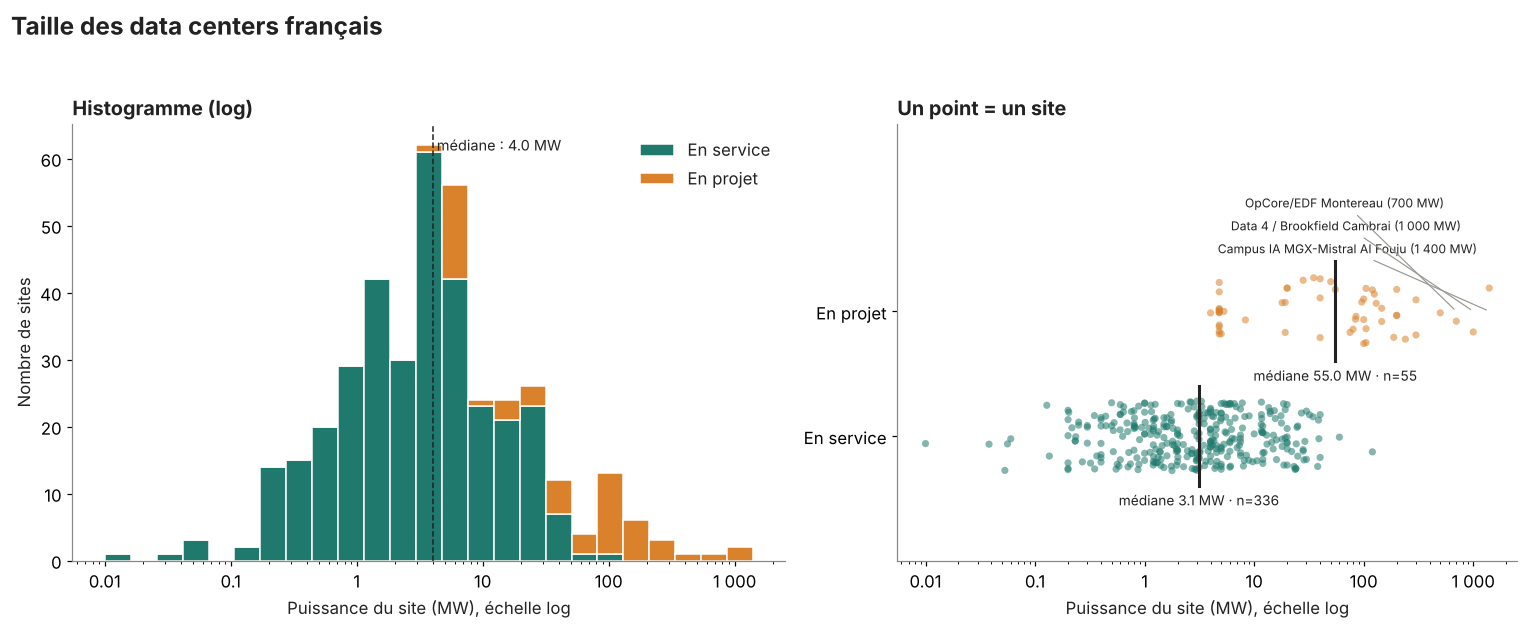

In [6]:
s = df.dropna(subset=["mw"])
bins = np.logspace(np.log10(s.mw.min()), np.log10(s.mw.max()), 26)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={"width_ratios": [1.15, 1]})

ax1.hist([s.loc[s.statut == "En service", "mw"], s.loc[s.statut == "En projet", "mw"]],
         bins=bins, stacked=True, color=[VERT, ORANGE], label=["En service", "En projet"], edgecolor="white")
ax1.set_xscale("log")
ax1.xaxis.set_major_formatter(mt.FuncFormatter(fmtlog))
ax1.set_xlabel("Puissance du site (MW), échelle log"); ax1.set_ylabel("Nombre de sites")
ax1.axvline(s.mw.median(), color=ENCRE, ls="--", lw=1)
ax1.text(s.mw.median() * 1.08, ax1.get_ylim()[1] * .94, f"médiane : {s.mw.median():.1f} MW", fontsize=9.5)
ax1.set_title("Histogramme (log)")
ax1.legend(frameon=False, loc="upper right")

rng = np.random.default_rng(1)
for i, (statut, c) in enumerate([("En service", VERT), ("En projet", ORANGE)]):
    v = s.loc[s.statut == statut, "mw"]
    ax2.scatter(v, i + rng.uniform(-.28, .28, len(v)), s=22, color=c, alpha=.55, edgecolor="none")
    ax2.plot([v.median()] * 2, [i - .4, i + .4], color=ENCRE, lw=2)
    ax2.text(v.median(), i - .45, f"médiane {v.median():.1f} MW · n={len(v)}", ha="center", va="top", fontsize=9)
for k, (_, r) in enumerate(s.nlargest(3, "mw").iterrows()):     # les 3 plus gros sites, étiquettes décalées
    i = 0 if r.statut == "En service" else 1
    ax2.annotate(f"{r['name'].strip()[:30]} ({fmt(r.mw)} MW)", (r.mw, i), xytext=(-8, 38 + k * 15), textcoords="offset points",
                 ha="right", fontsize=8, arrowprops=dict(arrowstyle="-", color=GRIS, lw=.8))
ax2.set_xscale("log"); ax2.set_yticks([0, 1], ["En service", "En projet"]); ax2.set_ylim(-1.0, 2.5)
ax2.xaxis.set_major_formatter(mt.FuncFormatter(fmtlog))
ax2.set_xlabel("Puissance du site (MW), échelle log")
ax2.set_title("Un point = un site")

fig.suptitle("Taille des data centers français", x=.01, ha="left", fontsize=16, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, .95))
plt.savefig("figures/4_distribution.png", bbox_inches="tight")
plt.show()

## 5. Concentration : courbe de Lorenz et part des plus gros sites
Plus la courbe s'écarte de la diagonale, plus la capacité est concentrée dans peu de sites.

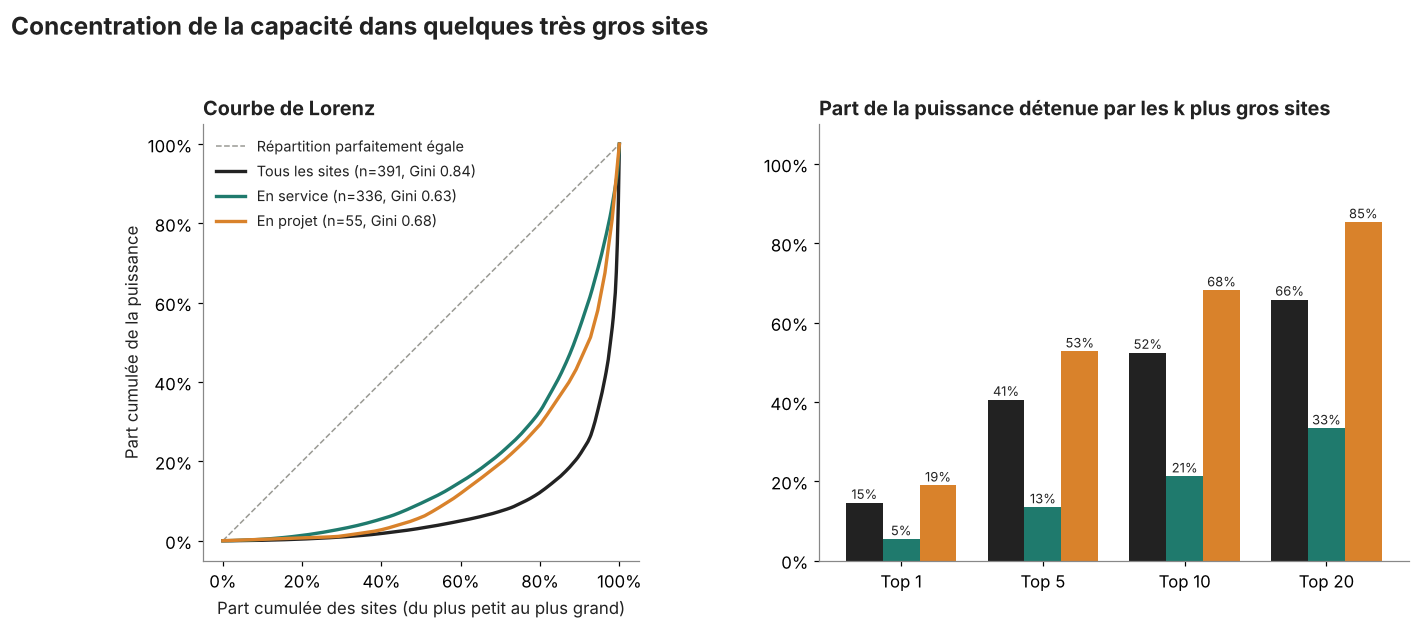

Top 10 des sites = 52% de la puissance totale ; sans le plus gros site : 47%


In [7]:
def lorenz(v):
    v = np.sort(np.asarray(v, float))
    c = np.insert(np.cumsum(v) / v.sum(), 0, 0)
    x = np.linspace(0, 1, len(c))
    gini = 1 - 2 * np.sum((c[1:] + c[:-1]) / 2 * np.diff(x))   # aire sous la courbe (trapèzes)
    return x, c, gini

def top_share(v, k=10):
    v = np.sort(np.asarray(v, float))[::-1]
    return v[:k].sum() / v.sum()

series = [("Tous les sites", s.mw, ENCRE), ("En service", s.loc[s.statut == "En service", "mw"], VERT),
          ("En projet", s.loc[s.statut == "En projet", "mw"], ORANGE)]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.8), gridspec_kw={"width_ratios": [1.2, 1]})
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="Répartition parfaitement égale")
for nom, v, c in series:
    x, cc, g = lorenz(v)
    ax.plot(x, cc, color=c, lw=2.2, label=f"{nom} (n={len(v)}, Gini {g:.2f})")
ax.set_xlabel("Part cumulée des sites (du plus petit au plus grand)")
ax.set_ylabel("Part cumulée de la puissance")
ax.xaxis.set_major_formatter(mt.PercentFormatter(1)); ax.yaxis.set_major_formatter(mt.PercentFormatter(1))
ax.set_title("Courbe de Lorenz"); ax.legend(frameon=False, loc="upper left", fontsize=9.5)
ax.set_aspect("equal")

ks = [1, 5, 10, 20]
w = .26
for i, (nom, v, c) in enumerate(series):
    vals = [top_share(v, k) for k in ks]
    b = ax2.bar(np.arange(len(ks)) + (i - 1) * w, vals, w, color=c, label=nom)
    for rect, val in zip(b, vals):
        ax2.text(rect.get_x() + rect.get_width() / 2, val + .01, f"{val:.0%}", ha="center", fontsize=8.5)
ax2.set_xticks(range(len(ks)), [f"Top {k}" for k in ks])
ax2.yaxis.set_major_formatter(mt.PercentFormatter(1)); ax2.set_ylim(0, 1.1)
ax2.set_title("Part de la puissance détenue par les k plus gros sites")

fig.suptitle("Concentration de la capacité dans quelques très gros sites", x=.01, ha="left", fontsize=16, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, .95))
plt.savefig("figures/5_concentration.png", bbox_inches="tight")
plt.show()

print(f"Top 10 des sites = {top_share(s.mw):.0%} de la puissance totale ; "
      f"sans le plus gros site : {top_share(s.mw.sort_values().iloc[:-1]):.0%}")

## 6. Carte temporelle avec curseur
Fais glisser l'année (ou clique sur ▶) pour voir les sites apparaître. Les sites sans année de mise en service sont masqués par défaut (case à cocher). Les anneaux pointillés = puissance non renseignée.

In [8]:
import folium
from branca.element import MacroElement, Template

pts = df.dropna(subset=["latitude", "longitude"])
pts = pts[pts.latitude.between(41, 51.5) & pts.longitude.between(-5.5, 9.8)]
print(f"{len(pts)} sites placés sur la carte, {len(df) - len(pts)} non affichés (sans coordonnées ou hors métropole)")

URL = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
geo = json.load(urllib.request.urlopen(URL))
noms_dep = {f["properties"]["code"]: f["properties"]["nom"] for f in geo["features"]}

def txt(v):
    return "" if pd.isna(v) else str(v).replace("\\,", "’").strip()

def code_dep(r):
    if pd.isna(r.department): return ""
    c = str(int(r.department)).zfill(2)
    if c == "20" and pd.notna(r.city_code):
        return "2A" if int(r.city_code) < 20200 else "2B"
    return c

def tip_html(r):
    mw = f"{r.mw:g} MW" if pd.notna(r.mw) else "<span style='color:#f0b27a'>Non renseignée</span>"
    an = f"{int(r.annee)}" if pd.notna(r.annee) else "Non renseignée"
    dep_code = code_dep(r); dep = noms_dep.get(dep_code, "")
    dep = f"{dep} ({dep_code})" if dep else (dep_code or "Inconnu")
    lignes = [("Nom", txt(r["name"])), ("Ville", txt(r.city_name).title() or "Inconnue"), ("Département", dep),
              ("Région", r.region), ("Opérateur", r.operateur), ("Puissance", mw),
              ("Mise en service" + (" prévue" if r.statut == "En projet" else ""), an)]
    return "".join(f"<div><span style='opacity:.65'>{k} :</span> <b>{v}</b></div>" for k, v in lignes)

data = [dict(lat=float(r.latitude), lon=float(r.longitude),
             rad=float(3 + (0 if pd.isna(r.mw) else r.mw) ** 0.5),
             statut="operating" if r.statut == "En service" else "project",
             manque=bool(pd.isna(r.mw)), mw=0.0 if pd.isna(r.mw) else float(r.mw),
             annee=None if pd.isna(r.annee) else int(r.annee), tip=tip_html(r))
        for r in pts.itertuples(index=False) for r in [pd.Series(r._asdict())]]

m = folium.Map(location=[46.6, 2.5], zoom_start=6, tiles=None)
folium.TileLayer(tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
                 attr="Tiles © Esri").add_to(m)
m.fit_bounds([[41.3, -5.2], [51.1, 9.6]])
folium.GeoJson(geo, style_function=lambda f: {"fillOpacity": 0, "color": "#b5b5b5", "weight": 0.5}).add_to(m)

m.get_root().header.add_child(folium.Element("""
<style>
.leaflet-tooltip.tt-dc{background:#1d1d1b;color:#f7f6f2;border:none;border-radius:8px;padding:8px 12px;
  font:13px/1.5 system-ui,Arial,sans-serif;box-shadow:0 2px 8px rgba(0,0,0,.35);white-space:normal;width:max-content;max-width:280px}
.leaflet-tooltip.tt-dc:before{display:none!important}
.legende-dc,.temps-dc{background:#fff;padding:10px 14px;border-radius:8px;box-shadow:0 1px 5px rgba(0,0,0,.3);
  font:13px/1.6 Arial,sans-serif;color:#222}
.temps-dc{width:300px}
.temps-dc .an{font-size:28px;font-weight:700;line-height:1.1}
.temps-dc input[type=range]{width:100%;margin:6px 0}
.temps-dc button{font:inherit;padding:2px 10px;cursor:pointer}
.temps-dc .cnt{color:#444;font-size:12.5px;margin-top:4px}
</style>"""))

class Points(MacroElement):
    _template = Template("""
    {% macro script(this, kwargs) %}
    var map = {{ this._parent.get_name() }};
    var DATA = {{ this.data|tojson }};
    var COL = {operating: '#1f7a6d', project: '#d9822b'};
    var layer = L.layerGroup().addTo(map);
    var MIN = 1985, MAX = 2035, START = 2026;

    var markers = DATA.map(function(d) {
        var c = COL[d.statut];
        var style = d.manque
            ? {radius: 7, color: c, weight: 2, dashArray: '3,3', fillColor: c, fillOpacity: 0.05}
            : {radius: d.rad, color: c, weight: 0.8, fillColor: c, fillOpacity: 0.5};
        var mk = L.circleMarker([d.lat, d.lon], style);
        mk.bindTooltip(d.tip, {sticky: true, className: 'tt-dc'});
        return mk;
    });

    var ctrl = L.control({position: 'topright'});
    var slider, lab, chk, cnt, timer = null, btn;
    ctrl.onAdd = function() {
        var div = L.DomUtil.create('div', 'temps-dc');
        div.innerHTML = '<b>Sites mis en service jusqu\\'à</b><div class="an"></div>'
            + '<input type="range" min="' + MIN + '" max="' + MAX + '" step="1" value="' + START + '">'
            + '<button type="button">▶ Lecture</button> '
            + '<label style="margin-left:8px"><input type="checkbox"> inclure les sites sans année</label>'
            + '<div class="cnt"></div>';
        lab = div.querySelector('.an'); slider = div.querySelector('input[type=range]');
        chk = div.querySelector('input[type=checkbox]'); btn = div.querySelector('button');
        cnt = div.querySelector('.cnt');
        slider.addEventListener('input', apply); chk.addEventListener('change', apply);
        btn.addEventListener('click', function() {
            if (timer) { clearInterval(timer); timer = null; btn.textContent = '▶ Lecture'; return; }
            if (+slider.value >= MAX) slider.value = MIN;
            btn.textContent = '⏸ Pause';
            timer = setInterval(function() {
                if (+slider.value >= MAX) { clearInterval(timer); timer = null; btn.textContent = '▶ Lecture'; return; }
                slider.value = +slider.value + 1; apply();
            }, 350);
        });
        L.DomEvent.disableClickPropagation(div);
        L.DomEvent.disableScrollPropagation(div);
        return div;
    };
    ctrl.addTo(map);

    function apply() {
        var Y = +slider.value, n = 0, nOp = 0, nPr = 0, mwOp = 0, mwPr = 0;
        layer.clearLayers();
        DATA.forEach(function(d, i) {
            var ok = (d.annee === null) ? chk.checked : (d.annee <= Y);
            if (!ok) return;
            layer.addLayer(markers[i]); n++;
            if (d.statut === 'operating') { nOp++; mwOp += d.mw; } else { nPr++; mwPr += d.mw; }
        });
        lab.textContent = Y + (Y > START ? '  (projection)' : '');
        function f(v) { return Math.round(v).toLocaleString('fr-FR'); }
        cnt.innerHTML = '<b>' + n + '</b> sites affichés<br>'
            + '<span style="color:#1f7a6d">●</span> en service : ' + nOp + ' sites, ' + f(mwOp) + ' MW<br>'
            + '<span style="color:#d9822b">●</span> en projet : ' + nPr + ' sites, ' + f(mwPr) + ' MW';
    }
    apply();
    {% endmacro %}
    """)
    def __init__(self, data):
        super().__init__(); self._name = "Points"; self.data = data
m.add_child(Points(data))

def rond(couleur, d=12, style="solid", fond="80"):
    return (f'<span style="display:inline-block;width:{d}px;height:{d}px;border-radius:50%;background:{couleur}{fond};'
            f'border:{2 if style == "dashed" else 1}px {style} {couleur};vertical-align:middle;margin:0 4px"></span>')

legende_html = f"""<b>Data centers</b><br>{rond(VERT)} En service<br>{rond(ORANGE)} En projet<br>
{rond("#555", 14, "dashed", "0d")} Puissance non renseignée<br>
<div style="margin-top:6px"><b>Taille = puissance (MW)</b></div>"""
class Legende(MacroElement):
    _template = Template("""
    {% macro script(this, kwargs) %}
    var legend = L.control({position: 'bottomleft'});
    legend.onAdd = function(map) { var div = L.DomUtil.create('div', 'legende-dc'); div.innerHTML = {{ this.html|tojson }}; return div; };
    legend.addTo({{ this._parent.get_name() }});
    {% endmacro %}
    """)
    def __init__(self, html):
        super().__init__(); self._name = "Legende"; self.html = html
m.add_child(Legende(legende_html))

m.save("carte_datacenters_temps.html")
m

416 sites placés sur la carte, 10 non affichés (sans coordonnées ou hors métropole)
